# Grinder Detection Algorithm

Cross-correlation based approach for detecting coffee grinder sound.

## Algorithm Overview
1. Load grinder reference recording and background noise
2. Analyze frequency signatures using Welch's method
3. Implement frame-based cross-correlation detector
4. Test with 48kHz and downsampled 8kHz (for ESP32-S3)

## Parameters
- Frame size: 512 samples
- Target sample rate for ESP32: 8kHz
- Smoothing window for energy detection

In [2]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from pathlib import Path

# Get script directory to handle paths correctly

## 1. Load Audio Files

In [3]:
# Load audio files
grinder_path = 'test_audio/grinder.wav'
background_path = 'test_audio/background-dishwasher.wav'

grinder_rate, grinder_audio = wavfile.read(str(grinder_path))
background_rate, background_audio = wavfile.read(str(background_path))

# Convert to float and normalize
grinder_audio = grinder_audio.astype(np.float32) / 32768.0
background_audio = background_audio.astype(np.float32) / 32768.0

print(f"\nGrinder: {grinder_rate}Hz, {len(grinder_audio)/grinder_rate:.2f}s, shape: {grinder_audio.shape}")
print(f"Background: {background_rate}Hz, {len(background_audio)/background_rate:.2f}s, shape: {background_audio.shape}")


Grinder: 48000Hz, 6.03s, shape: (289262,)
Background: 48000Hz, 5.91s, shape: (283584,)


/var/folders/qn/44jp2kl51j96qk1dkvr_mmyw0000gn/T/ipykernel_89369/3264957068.py:5: WavFileWarning: Chunk (non-data) not understood, skipping it.
  grinder_rate, grinder_audio = wavfile.read(str(grinder_path))



Saved: welch_psd_48khz.png


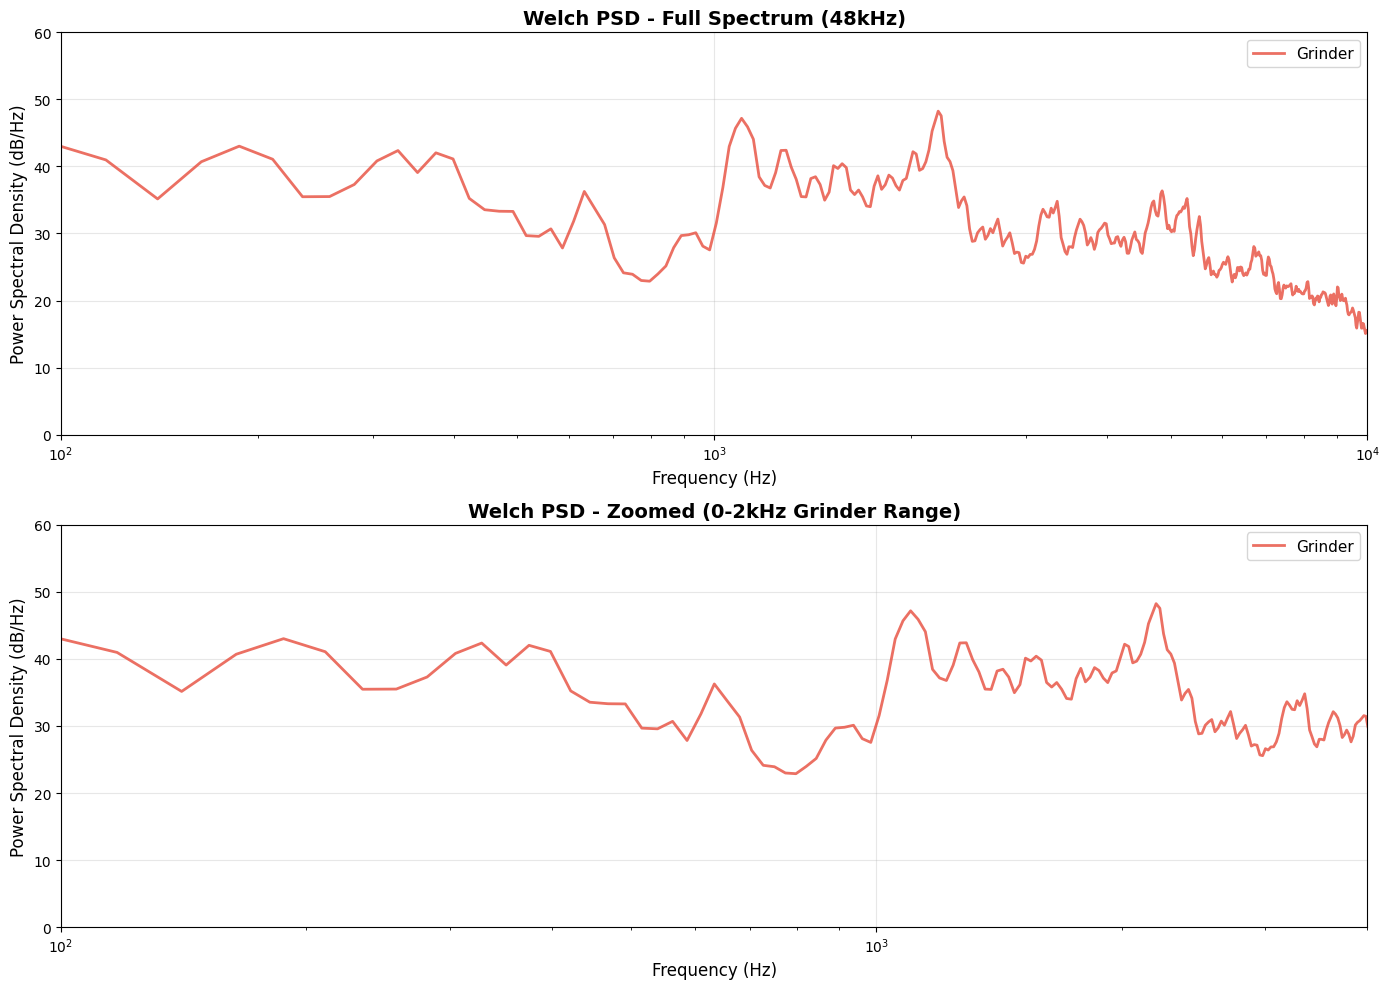


Frequency Analysis:
  Grinder peak frequency: 2203.1 Hz
  Background peak frequency: 164.1 Hz


In [13]:
# Welch's method for power spectral density
nperseg = 2048  # FFT window size

# Compute PSD
f_grinder, psd_grinder = signal.welch(grinder_audio, grinder_rate, nperseg=nperseg)
f_background, psd_background = signal.welch(background_audio, background_rate, nperseg=nperseg)

# Plot frequency signatures
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10))

# Plot 1: Full spectrum (log scale)
ax1.semilogx(f_grinder, 10*np.log10(psd_grinder + 1e-10), label='Grinder', alpha=0.8, linewidth=2, color='#e74c3c')
# ax1.semilogy(f_background, psd_background, label='Background (Dishwasher)', alpha=0.8, linewidth=2, color='#3498db')
ax1.set_xlabel('Frequency (Hz)', fontsize=12)
ax1.set_ylabel('Power Spectral Density (dB/Hz)', fontsize=12)
ax1.set_title('Welch PSD - Full Spectrum (48kHz)', fontsize=14, fontweight='bold')
ax1.legend(fontsize=11)
ax1.grid(True, alpha=0.3)
ax1.set_xlim(100, 10000)  # Focus on 0-4kHz
ax1.set_ylim(0, 60)

# Plot 2: Zoomed view (0-2kHz typical grinder range)
ax2.semilogx(f_grinder, 10*np.log10(psd_grinder + 1e-10), label='Grinder', alpha=0.8, linewidth=2, color='#e74c3c')
# ax2.semilogy(f_background, psd_background, label='Background (Dishwasher)', alpha=0.8, linewidth=2, color='#3498db')
ax2.set_xlabel('Frequency (Hz)', fontsize=12)
ax2.set_ylabel('Power Spectral Density (dB/Hz)', fontsize=12)
ax2.set_title('Welch PSD - Zoomed (0-2kHz Grinder Range)', fontsize=14, fontweight='bold')
ax2.legend(fontsize=11)
ax2.grid(True, alpha=0.3)
ax2.set_xlim(100, 4000)
ax2.set_ylim(0, 60)

plt.tight_layout()
plt.savefig('welch_psd_48khz.png', dpi=150, bbox_inches='tight')
print("\nSaved: welch_psd_48khz.png")
plt.show()

print(f"\nFrequency Analysis:")
print(f"  Grinder peak frequency: {f_grinder[np.argmax(psd_grinder)]:.1f} Hz")
print(f"  Background peak frequency: {f_background[np.argmax(psd_background)]:.1f} Hz")